# Final FNEWS research summary

**Research objective.** Provide a presentation-ready overview grounded in verified local artifacts.

All results are read from local FNEWS artifacts. `SOURCE_TRUE` and `SOURCE_NON_TRUE` are Fakeddit source-taxonomy labels, not independently verified factuality labels. The held-out test partition is not opened by these notebooks except where a prior frozen metric is explicitly quoted.

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
if not (ROOT / "data/research_dataset").exists():
    ROOT = Path("/Users/aka_ank/Desktop/FNEWS")
DATA = ROOT / "data/research_dataset"
REPORTS = ROOT / "reports"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.titlesize": 13, "axes.labelsize": 11})

def paired(split):
    frame = pd.read_parquet(DATA / "manifests" / f"{split}_manifest.parquet")
    return frame.loc[(frame.source_dataset == "Fakeddit") & (frame.download_status == "verified_reused_or_processed")].copy().reset_index(drop=True)

def canonical_source_labels(raw):
    """Fakeddit raw 1=true; return 0=SOURCE_TRUE, 1=SOURCE_NON_TRUE."""
    return 1 - np.asarray(raw, dtype=int)

def source_names(values):
    return np.where(np.asarray(values) == 0, "SOURCE_TRUE", "SOURCE_NON_TRUE")

def show_frame(frame, rows=10):
    display(frame.head(rows))


## Problem, objective, and pipeline

FNEWS studies source-taxonomy classification of paired Reddit text and images. The pipeline is: official metadata → verified bounded pairs → leakage controls → train-only preprocessing → saved baselines/fusion experiments → validation-only diagnostics → guarded local URL/text workflow. It is not a general-purpose factual-truth verifier.

## EDA totals at a glance

The dataset EDA confirms that this research version contains only verified text-image pairs. Fakeddit raw label `1` maps to `SOURCE_TRUE`; raw label `0` maps to the broader `SOURCE_NON_TRUE` taxonomy. The diagram below is an EDA summary, not a performance chart.

In [2]:
splits={s:paired(s) for s in ['train','validate','test']}
eda=pd.DataFrame([{'split':s.title(),'pairs':len(frame),'SOURCE_TRUE':int((frame.fake_news_label==1).sum()),'SOURCE_NON_TRUE':int((frame.fake_news_label==0).sum())} for s,frame in splits.items()]);display(eda)
print('Total verified paired samples:',int(eda.pairs.sum()))
print('Total SOURCE_TRUE:',int(eda.SOURCE_TRUE.sum()),'| Total SOURCE_NON_TRUE:',int(eda.SOURCE_NON_TRUE.sum()))

,split,pairs,SOURCE_TRUE,SOURCE_NON_TRUE
0,Train,2353,1199,1154
1,Validate,933,377,556
2,Test,947,382,565


Total verified paired samples: 4233
Total SOURCE_TRUE: 1958 | Total SOURCE_NON_TRUE: 2275


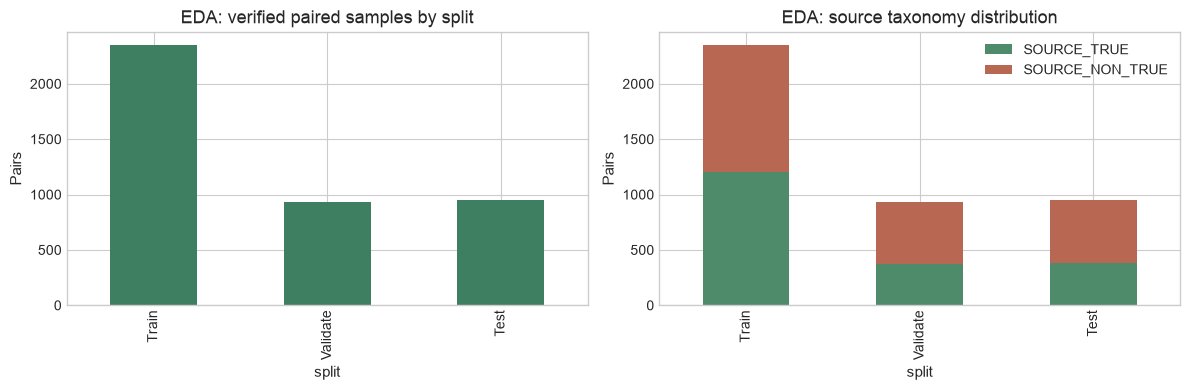

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4));eda.set_index('split')['pairs'].plot.bar(ax=axes[0],color='#3f7f61',title='EDA: verified paired samples by split');axes[0].set_ylabel('Pairs')
eda.set_index('split')[['SOURCE_TRUE','SOURCE_NON_TRUE']].plot.bar(stacked=True,ax=axes[1],color=['#4e8b6a','#b86753'],title='EDA: source taxonomy distribution');axes[1].set_ylabel('Pairs');plt.tight_layout();plt.show()

## Training methodology

**Text baseline.** The active TF-IDF + LinearSVC model learns a maximum-margin decision boundary from cleaned Fakeddit titles. The vectorizer is fitted on training text only with up to 50,000 unigram/bigram features, `min_df=2`, sublinear term frequency, and L2 normalization. A LinearSVC margin is not a calibrated probability.

**Image baseline.** ResNet-18 uses ImageNet preprocessing and a two-class head on local images. Image-only results are limited because an image cannot independently establish the factual status of a title.

**Fusion experiments.** Weighted late fusion combines compatible calibrated source-non-true probabilities with alpha 0.41/0.59. CLIP gated fusion combines frozen 512-D image and text embeddings with a learned feature-wise sigmoid gate. Both are retained research artifacts; the latter is archived/inactive in the website.

In [4]:
svm=joblib.load(REPORTS/'experiments/research_dataset_baselines/tfidf_svm/model.joblib');print('Saved TF-IDF + LinearSVC configuration:');print(svm)
history=pd.read_csv(REPORTS/'experiments/research_dataset_baselines/resnet18_frozen/history.csv');print('ResNet history columns:',history.columns.tolist());print('Weighted late-fusion alpha:',json.loads((REPORTS/'weighted_late_fusion_v1/metrics.json').read_text())['alpha'])

Saved TF-IDF + LinearSVC configuration:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=50000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('svm', LinearSVC())])
ResNet history columns: ['epoch', 'train_loss', 'validation_macro_f1']
Weighted late-fusion alpha: 0.41000000000000003


In [5]:
state=json.loads((ROOT/'PROJECT_STATE.json').read_text());display(pd.DataFrame(state['phase_status_checklist']))

,phase,status,evidence,metrics,next_action
0,Validated Fakeddit research dataset,completed,"4,233 verified pairs; leakage report; 0.158 GiB","2,353/933/947 train/validation/test",Preserve split and 20 GiB cap
1,Frozen gated-fusion baseline,completed,checkpoint hash and saved metrics verified,"validation 87.46% accuracy, 87.07% macro-F1; h...",Do not tune on test
2,Secure URL multimodal inference,completed,controlled URL-to-fusion workflow plus runtime...,85 tests passed; API smoke exposed non_true/tr...,Use only with explicit research-label warning
3,External compatibility and acquisition,completed,five-candidate review; ReCOVery 100-record pilot,"66 validated pairs, 34 inaccessible images",Retain source labels; seek compatible split-de...
4,External zero-shot evaluation,deferred,intentionally deferred by user; prior data/lab...,not measured,Do not perform external discovery or evaluatio...
5,Modality contribution,completed,frozen 933-sample validation perturbation run,paired 87.07 macro-F1; shuffled image 70.77; s...,Use only as sensitivity evidence
6,Probability calibration,completed,stratified validation-half fit and assessment,assessment ECE 0.0889→0.0380; Brier 0.1017→0.0898,Monitor transfer before relying on calibrated ...
7,Explainability,in_progress,gate/norm/perturbation diagnostics executed,mean text gate 0.519 ± 0.190,Run registered raw-image and token attribution...
8,Robustness,in_progress,16-pair pilot and independent 32-pair 19-condi...,32-pair blur sigma 3 macro-F1 77.03%; full par...,Decide whether a registered full-partition or ...
9,Live-publisher URL QA,blocked,Reuters/AP access denials and Guardian Develop...,zero authorized compatible publisher inputs af...,Resume only with a source explicitly authorizi...


,accuracy,macro_f1,source_true_recall,source_non_true_recall,balanced_accuracy,matrix
TF-IDF + LinearSVC (active),0.720257,0.717136,0.761273,0.692446,0.72686,"[[287, 90], [171, 385]]"
ResNet-18 frozen,0.693462,0.686088,0.668435,0.710432,0.689433,"[[252, 125], [161, 395]]"
Weighted late fusion,0.764202,0.759459,0.771883,0.758993,0.765438,"[[291, 86], [134, 422]]"
CLIP gated fusion (archived),0.874598,0.8707,0.867374,0.879496,0.873435,"[[327, 50], [67, 489]]"


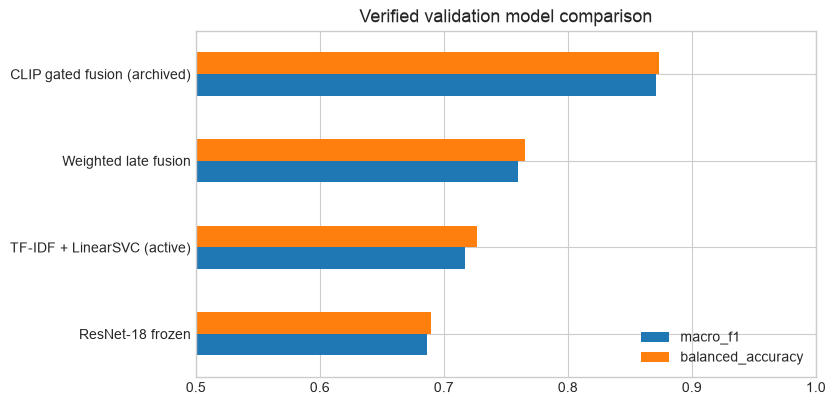

In [6]:
reliability=json.loads((REPORTS/'root_cause/classification_reliability_metrics.json').read_text());comparison=pd.DataFrame(reliability['model_metrics']).T;display(comparison[['accuracy','macro_f1','source_true_recall','source_non_true_recall','balanced_accuracy','matrix']])
comparison[['macro_f1','balanced_accuracy']].sort_values('macro_f1').plot.barh(title='Verified validation model comparison');plt.xlim(.5,1);plt.show()

## Final findings

The archived CLIP gated model has the strongest saved matched validation result, but remains inactive. Weighted late fusion improves the active SVM on the selection validation set but has no independent post-selection validation. The active dashboard deliberately uses the verified text-only SVM and names its result SOURCE_TRUE/SOURCE_NON_TRUE.

### Limitations and future work

The dataset’s taxonomy includes satire, misleading content, false connection, and manipulation; it is not independently verified live-news truth. External zero-shot evaluation and image-text mismatch detection remain user-deferred. Any future deployment decision requires legally usable external data, explicit labels, a frozen protocol, and an untouched evaluation split.

In [7]:
print('Checkpoint preservation:',state['phase_status_checklist'][1]['evidence']);print('No notebook in this suite trains a model or reads the held-out test manifest for selection.')

Checkpoint preservation: checkpoint hash and saved metrics verified
No notebook in this suite trains a model or reads the held-out test manifest for selection.
